In [14]:
import numpy as np
from hcipy import * 
import os
import sys
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
from scipy.optimize import curve_fit

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2
from psfGenerator import PsfGenerator

In [15]:
params = {'legend.fontsize': 'x-large',
          'figure.titlesize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

In [16]:
jay = read_fits('/Users/Katie/Downloads/jay_hr4796_23a/stackall_mean_profilesub.fits')
alycia_r = read_fits('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/camsci2_20260420234915213970330.fits')

In [17]:
dim = np.sqrt(jay.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
jay = Field(jay.ravel(),pgrid)

In [18]:
dim = np.sqrt(alycia_r.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
alycia_r = Field(alycia_r.ravel(),pgrid)

In [19]:
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)
jay = ADC.crop_image(jay,extent=150,mask_diam=0)
alycia_r = ADC.crop_image(alycia_r,extent=150,mask_diam=0)

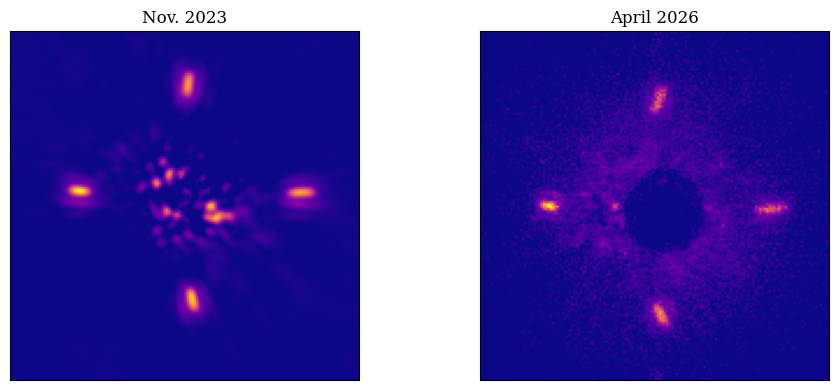

In [26]:
fig, ax = plt.subplots(1,2,figsize=(10,4))

imshow_field(jay,ax=ax[0],cmap='plasma')
ax[0].set_title('Nov. 2023')
ax[0].set_xticks([])
ax[0].set_yticks([])


imshow_field(alycia_r,ax=ax[1],cmap='plasma')
ax[1].set_title('April 2026')
ax[1].set_xticks([])
ax[1].set_yticks([])

fig.tight_layout()

In [27]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/hallofshame.png',dpi=300)